# Intro

In [9]:
import pandas as pd

df = pd.read_csv("Depot_sales.csv", header=0, parse_dates=["date"], index_col="date")
cut = int(len(df) * 2/3)

df_fit = df.iloc[:cut] #4 years of the series
df_test = df.iloc[cut:] #2 years of the series (years 5 and 6)



print(df["Product_A"])
print(df_test)

date
2020-01-01    43.0
2020-01-02    41.0
2020-01-03    43.0
2020-01-04    43.0
2020-01-05    41.0
              ... 
2025-12-27    46.0
2025-12-28    49.0
2025-12-29    46.0
2025-12-30    46.0
2025-12-31    45.0
Name: Product_A, Length: 2192, dtype: float64
            Product_A  Product_B  Product_C
date                                       
2024-01-01       41.0       54.0       38.0
2024-01-02       43.0       54.0       41.0
2024-01-03       45.0       52.0       38.0
2024-01-04       42.0       50.0       38.0
2024-01-05       41.0       51.0       39.0
...               ...        ...        ...
2025-12-27       46.0       51.0       45.0
2025-12-28       49.0       49.0       46.0
2025-12-29       46.0       50.0       47.0
2025-12-30       46.0       48.0       42.0
2025-12-31       45.0       53.0       45.0

[731 rows x 3 columns]


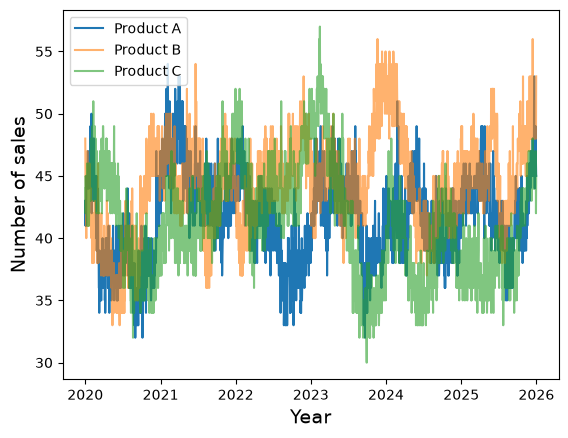

In [5]:
from matplotlib import pyplot as plt
import matplotlib.dates as mdates

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], label="Product A")
ax.plot(df.index, df["Product_B"], label ="Product B",alpha = 0.6)
ax.plot(df.index, df["Product_C"], label="Product C", alpha= 0.6)
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()



In [ ]:
import numpy as np

yearly_means = (
    df.groupby(df.index.year)[["Product_A", "Product_B", "Product_C"]]
    .mean()
    .rename_axis("Year")
    .round(2)
)
yearly_means

,Product_A,Product_B,Product_C
Year,,,
2020,38.83,40.63,40.80
2021,44.52,44.44,42.22
2022,40.20,44.69,44.20
2023,41.81,45.50,41.47
2024,41.33,44.55,38.89
2025,42.45,45.69,38.94


### Performing a simple linear regression fit using generalised least squares to predict future price behaviour.

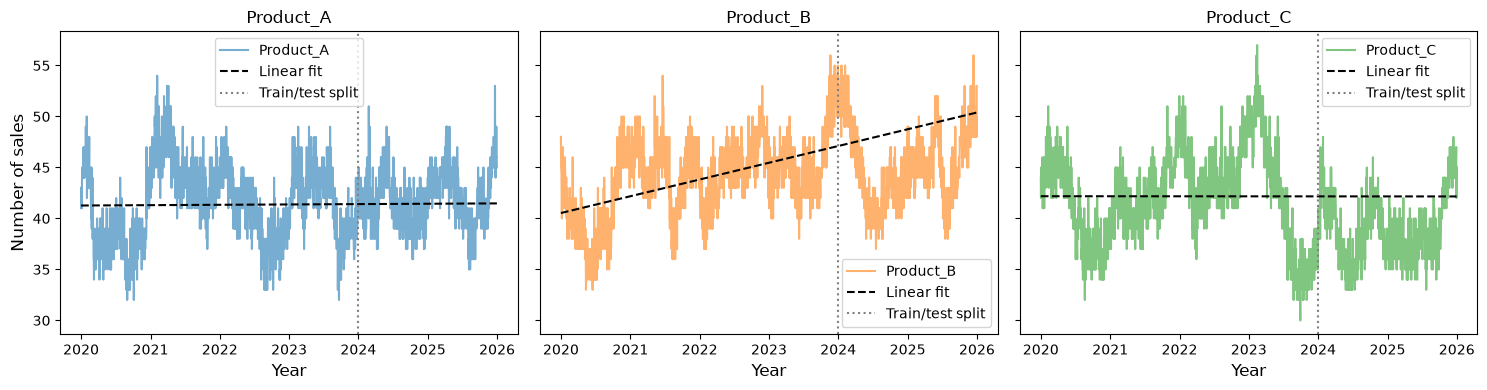

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
1,Product_B,OLS,3.29,5.24
2,Product_C,OLS,4.55,4.54


In [23]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from scipy import stats
from sklearn.metrics import root_mean_squared_error 


products = ["Product_A", "Product_B", "Product_C"]
colours = {"Product_A": "tab:blue", "Product_B": "tab:orange", "Product_C": "tab:green"}

# Time as days since the start of the series
t0 = df.index[0]
days_all = (df.index - t0).days.to_numpy()
days_fit = (df_fit.index - t0).days.to_numpy()
days_test = (df_test.index - t0).days.to_numpy()

results = []  # shared scoreboard: later models append rows in the same format
    
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()
    # Fit on the training period only, then predict across the whole series
    fit = stats.linregress(days_fit, df_fit[p])
    predict = lambda d: fit.intercept + fit.slope * d
    #predict = fit.intercept + fit.slope * days_all

    rmse_train = root_mean_squared_error(y_fit, predict(days_fit))
    rmse_test = root_mean_squared_error(y_test, predict(days_test))
    
    training_results = {"Product": p, "Method": "OLS", "RMSE train": rmse_train, "RMSE test": rmse_test}
    results.append(training_results)

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df.index, predict(days_all), color="black", linestyle="--", label="Linear fit")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).round(2)


### The linear fits do give good results for mean (based off the regression fit) and low p-values but due to correaltion as it is a time series and visually it clearly is missing a significant amount of the behaviour of the curve, though they are cheap to calculate.

### Using a non-linear curve fit instead

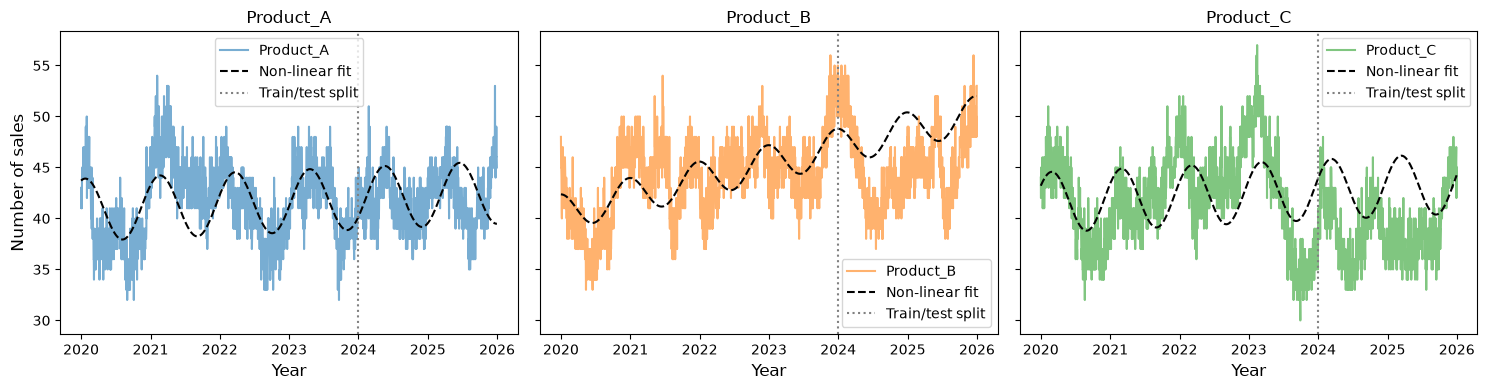

,Product,Method,RMSE train,RMSE test
0,Product_A,OLS,3.85,2.80
3,Product_A,Harmonic regression,3.16,3.43
4,Product_B,Harmonic regression,3.04,4.92
1,Product_B,OLS,3.29,5.24
2,Product_C,OLS,4.55,4.54
5,Product_C,Harmonic regression,4.06,5.68


In [24]:
from scipy.optimize import curve_fit

def seasonal_trend(x, a, c, w, trend, const):
    return a * np.sin(w * x) + c * np.cos(w * x) + trend * x + const

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)

for ax, p in zip(axes, products):
    y_fit = df_fit[p].to_numpy()
    y_test = df_test[p].to_numpy()

    # Starting guesses: annual cycle, no trend, centred on the training mean
    p0 = [y_fit.std(), y_fit.std(), 2 * np.pi / 365.25, 0.0, y_fit.mean()]

    # Fit on training data
    params, _ = curve_fit(seasonal_trend, days_fit, y_fit, p0=p0, method="trf", maxfev=20000)
    predict = lambda d: seasonal_trend(d, *params)
    #print(params)

    # fitting_period = np.round(2 * np.pi / abs(params[2], 2))
    # print("fitted period is ", fitting_period, " days")

    rmse_train = root_mean_squared_error(y_fit, predict(days_fit))
    rmse_test = root_mean_squared_error(y_test, predict(days_test))

    results.append({"Product": p, "Method": "Harmonic regression", "RMSE train": rmse_train, "RMSE test": rmse_test})

    ax.plot(df.index, df[p], color=colours[p], alpha=0.6, label=p)
    ax.plot(df.index, predict(days_all), color="black", linestyle="--", label="Non-linear fit")
    ax.axvline(df_test.index[0], color="grey", linestyle=":", label="Train/test split")

    ax.set_title(p)
    ax.set_xlabel("Year", fontsize=12)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    ax.legend()

axes[0].set_ylabel("Number of sales", fontsize=12)
plt.tight_layout()
plt.show()

pd.DataFrame(results).sort_values(["Product", "RMSE test"]).round(2)

In [ ]:
from scipy.optimize import curve_fit
import numpy as np

products = ["Product_A", "Product_B", "Product_C"]
colours = {"Product_A": "tab:blue", "Product_B": "tab:orange", "Product_C": "tab:green"}

# Time as days since the start of the series
t0 = df.index[0]
days_all = (df.index - t0).days.to_numpy()
days_fit = (df_fit.index - t0).days.to_numpy()
days_test = (df_test.index - t0).days.to_numpy()

def func(x, a, b, c, d, const):
    return a * np.sin(b*x) + c * np.cos(d*x) + const

NonL_fit = curve_fit(func, t, df["Product_A"], p0=[0.1, 0.1, 0.1, 0.1, 0.2], method="trf")

print(NonL_fit)
NonL_params = NonL_fit[0]
print(NonL_params)
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-func(x, NonL_params[0], NonL_params[1], NonL_params[2], NonL_params[3]))**2))

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], alpha=0.5, label="Actual")
ax.plot(df.index, func(t, NonL_params[0], NonL_params[1], NonL_params[2], NonL_params[3]), label="Non-linear least squares fit")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()
print("MSE is ", RMSE)

RuntimeError: Optimal parameters not found: The maximum number of function evaluations is exceeded.

### Kernel ridge regression

{'alpha': 1, 'gamma': 20}


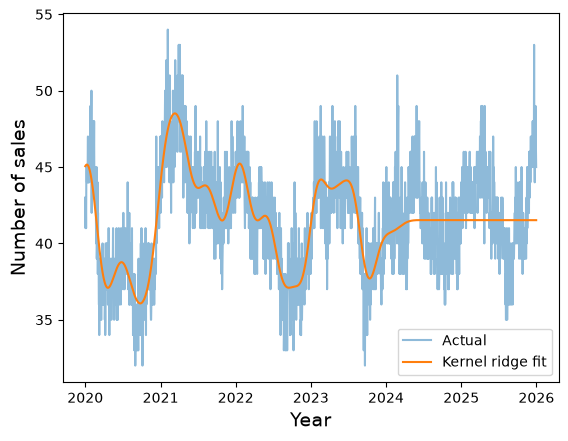

RMSE is  0.10377765048294589


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.kernel_ridge import KernelRidge
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

t = np.asarray((df.index - df.index[0]).days, dtype=float)
t_fit = np.asarray((df_fit.index - df_fit.index[0]).days, dtype=float)
X = (t / 365.25).reshape(-1, 1)
X_fit = (t_fit / 365.25).reshape(-1, 1)
y_fit = df_fit["Product_A"].to_numpy(dtype=float)
y = df["Product_A"].to_numpy(dtype=float)
y_fit_mean = y_fit.mean() #The central target
y_mean = y.mean()

grid = GridSearchCV(
    KernelRidge(kernel="rbf"),
    param_grid={"alpha": [0.01, 0.1, 1, 10], "gamma": [1, 5, 20, 50, 100]},
    cv=TimeSeriesSplit(n_splits=5),
    scoring="neg_mean_absolute_error",
)
grid.fit(X_fit, y_fit-y_fit_mean)
print(grid.best_params_)

best = grid.best_estimator_
fitted = best.predict(X) + y_mean
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-fitted)**2))

fig, ax = plt.subplots()
ax.plot(df.index, y, alpha=0.5, label="Actual")
ax.plot(df.index, fitted, label="Kernel ridge fit")
ax.plot(df.index, )
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()

print("RMSE is ", RMSE)

### Holt-Winters exponential curve smoothing used to statistical model the time series

ValueError: x and y must have same first dimension, but have shapes (2192,) and (1461,)

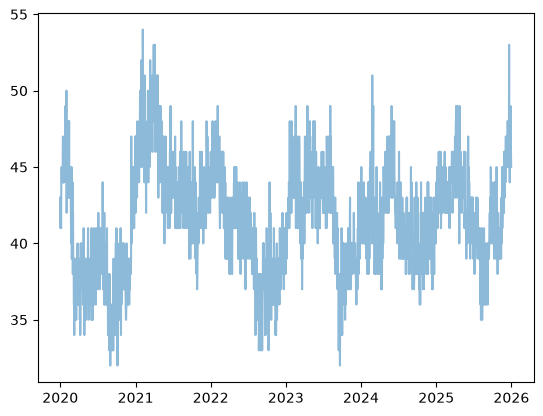

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.holtwinters import ExponentialSmoothing

#df = pd.read_csv("Depot_sales.csv", parse_dates=["date"], index_col="date")
df_freq = df_fit.asfreq("D")                      # daily frequency on the index

#split = int(len(df) * 0.8)
#train, test = df.iloc[:split], df.iloc[split:]

HW_model = ExponentialSmoothing(
    df_freq["Product_A"],
    trend="add",                         # linear trend
    damped_trend=True,                   # stops the trend extrapolating forever
    seasonal="add",                      # additive seasonality
    seasonal_periods=365,                # must be an integer
    initialization_method="heuristic",   # Best for long term periods
).fit()

fitted = HW_model.fittedvalues              #fitted curve
RMSE = np.sqrt(1/sum(x) * sum((df["Product_A"]-fitted)**2))

#print(HW_model.params)                      

fig, ax = plt.subplots()
ax.plot(df.index, df["Product_A"], alpha=0.5, label="Actual")
ax.plot(df.index, fitted, label="Holt-Winters fit")
ax.set_xlabel("Year", fontsize=14)
ax.set_ylabel("Number of sales", fontsize=14)
ax.legend()
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend()
plt.show()
print("RMSE is ", RMSE)



In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.metrics import mean_absolute_error, mean_squared_error

def check_stationarity(timeseries):
    result = adfuller(timeseries, autolag='AIC')
    p_value = result[1]
    print(f'ADF Statistic: {result[0]}')
    print(f'p-value: {p_value}')
    print('Stationary' if p_value < 0.05 else 'Non-Stationary')


check_stationarity(df["Product_A"])

ADF Statistic: -1.7522624095992545
p-value: 0.4044061422892259
Non-Stationary


C:\Users\joe\AppData\Local\Temp\ipykernel_1176\535396099.py:2: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  result = adfuller(timeseries, autolag='AIC')


### Distribution is non-stationary therefore SARIMA is not applicable


